# Session 12 lecture: Marketing: campaign evaluation

<p class="lead">
Marketing dashboards are full of rates: click-through, conversion, cost per acquisition, return on ad spend. This lecture shows how to calculate them so they add up, how a small campaign can make a whole channel look better than it is, and why "this campaign earned the most revenue per unit of spend" is not the same as "give it more money".
</p>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aayush181509/AnalyticsLecture/blob/main/notebooks/12_marketing_campaigns_lecture.ipynb)

Open this notebook in Google Colab with the button above, then run each cell from top to bottom with **Shift + Enter**. Save your own copy with **File → Save a copy in Drive**.

---

## Recap quiz

Before we start, answer these questions on the [Session 11 lecture](11_operations_service_lecture.md). Write short answers; we discuss them together.

1. To measure on-time delivery for last month, which shipments belong in the denominator: the ones **delivered** last month, or the ones **due** last month? Why does it matter?
2. Some shipments that were due last month have still not arrived. A colleague drops them because "they have no delivery date yet". What happens to the on-time rate, and why is that misleading?
3. Lead times are skewed: most shipments take a few days, a few take weeks. Which would you report as the "typical" lead time, the mean or the median? What extra number would you add?
4. Two carriers have on-time rates of 95% and 90%. What else must you know before you call the first one better?

---

## What you will be able to explain

1. The **decision** a campaign review supports, and why its answer is usually "test this", not "move all the money".
2. The **marketing funnel** (impressions → clicks → sessions → conversions) and the **grain** of a campaign-day table.
3. Five funnel rates, **CTR, conversion rate, CPC, CPA and ROAS**, each calculated as a **ratio of sums**.
4. What to do when a denominator is **zero**, and which rows are **review cases**.
5. Why the **mean of campaign rates** can rank channels in the wrong order, while the **weighted rate** does not.
6. What **attributed** revenue can and cannot tell you, and why **ROAS** is neither profit nor proof that the spend caused the sales.
7. How to turn a promising comparison into a **controlled test** of a budget change.

This lecture builds on [Metrics and KPIs](05_metrics_and_kpis_lecture.md) (weighted rates), [Correlation and regression](08_correlation_and_regression_lecture.md) (confounding) and [Sampling, uncertainty and experiments](09_sampling_and_experiments_lecture.md) (A/B tests). In the **Lab** you build the campaign scorecard yourself and write a test proposal.

> **How to use the questions in this notebook**
>
> **Predict, then reveal** boxes ask you to guess before running the next cell. Write your guess down first. **Check your understanding** boxes are short questions to answer in your own words.

Run the setup cells first: one loads the synthetic marketing data, the next sets the chart style, and the third defines three small helper functions we use all session.

In [1]:
# Marketing data setup (synthetic). Run this cell first.
# Downloads the course's synthetic marketing data from GitHub and checks it is the exact version this course uses.
import hashlib
import io
import os
import urllib.request

import pandas as pd

MARKETING_URL = "https://raw.githubusercontent.com/Aayush181509/AnalyticsLecture/main/data/synthetic/marketing-v1/"
MARKETING_SHA256 = {
    "marketing_daily.csv": "1cbfc8e1c91ae72d18364b2d13bdf6db513c4aec28c339ef8b91f87a60dc0a07",
    "ab_test.csv": "41a3662997111b66d7ab1eb899f4b32e26bd64c66284ce881db6b8a7300ad47f",
}
MARKETING_DIR = os.environ.get("COURSE_MARKETING_DIR", "")


def load_marketing(name):
    """Load one marketing-v1 file: 'marketing_daily.csv' or 'ab_test.csv'."""
    if MARKETING_DIR:
        with open(os.path.join(MARKETING_DIR, name), "rb") as f:
            data = f.read()
    else:
        data = urllib.request.urlopen(MARKETING_URL + name).read()
    if hashlib.sha256(data).hexdigest() != MARKETING_SHA256[name]:
        print("WARNING: this file differs from the course version. Ask your facilitator.")
    return pd.read_csv(io.BytesIO(data), parse_dates=["date"])


print("Marketing setup complete.")

Marketing setup complete.


In [2]:
import matplotlib.pyplot as plt
import numpy as np

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({
    "figure.figsize": (8, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a"]),
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})
print("Plot style ready.")

Plot style ready.


In [3]:
COUNTS = ["spend", "impressions", "clicks", "sessions", "conversions", "attributed_revenue"]


def safe_div(numerator, denominator):
    """numerator / denominator, left blank (NaN) wherever the denominator is 0."""
    return numerator / denominator.where(denominator != 0)


def add_rates(totals):
    """Add the five funnel rates to a table of SUMMED counts (ratios of sums)."""
    t = totals.copy()
    t["CTR"] = safe_div(t["clicks"], t["impressions"])
    t["conv_rate"] = safe_div(t["conversions"], t["sessions"])
    t["CPC"] = safe_div(t["spend"], t["clicks"])
    t["CPA"] = safe_div(t["spend"], t["conversions"])
    t["ROAS"] = safe_div(t["attributed_revenue"], t["spend"])
    return t


def show(table):
    """Format a totals table for reading. Blank rates show as 'n/a' (not available)."""
    out = table.copy()
    for col in out.columns:
        if col in ("CTR", "conv_rate", "share of spend", "share of conversions"):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:.2%}")
        elif col in ("spend", "attributed_revenue", "CPC", "CPA", "ROAS"):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.2f}")
        elif pd.api.types.is_numeric_dtype(out[col]):
            out[col] = out[col].map(lambda v: "n/a" if pd.isna(v) else f"{v:,.0f}")
    return out


print("Helpers ready: safe_div, add_rates, show.")

Helpers ready: safe_div, add_rates, show.


---

## Part 1: The decision

> *Marketing lead: "Next quarter's budget is fixed. I want to move some money towards the campaigns that work best, but I can only defend a change I can measure. Which campaigns deserve a **controlled budget change**, and how would we know if it worked?"*

Notice what the lead is **not** asking. She does not want a ranking to copy into next quarter's plan. She wants a short list of candidates and a way to test them. That shapes the whole analysis:

| Step | Question for this case |
|---|---|
| **Question** | Which campaigns are efficient **and** big enough to matter? |
| **Understanding** | What does one row mean? What does "conversion" and "revenue" mean here? |
| **Preparation** | Are the keys unique? Do the funnel counts make sense? Where are the zero denominators? |
| **Analysis** | Funnel rates as ratios of sums, by campaign and channel, with volumes |
| **Validation** | Do campaign totals add up to the company total? Do rankings survive weighting? |
| **Recommendation** | Which change to **test**, how, for how long, and what would count as success |

> **About the data**
>
> `marketing_daily.csv` is **synthetic** teaching data generated by the course. It describes no real company, brand, person or advertising platform. Money is in neutral **currency units**. The same file was used in Session 8.

In [4]:
daily = load_marketing("marketing_daily.csv")
print("Rows:", len(daily))
print("Dates:", daily["date"].min().date(), "to", daily["date"].max().date())
daily.head()

Rows: 2555
Dates: 2025-01-01 to 2025-12-31


,date,campaign_id,campaign_name,channel,spend,impressions,clicks,sessions,conversions,attributed_revenue
0,2025-01-01,DISP-01,Display - partner sites,Display,575.20,175974,633,449,2,150.53
1,2025-01-01,EML-01,Email - newsletter,Email,45.78,74237,563,536,16,"1,403.35"
2,2025-01-01,SOC-01,Social - broad audience,Social,998.65,135199,1651,1301,12,946.74
3,2025-01-01,SOC-02,Social - past visitors,Social,60.57,6692,136,117,8,982.79
4,2025-01-01,SRCH-01,Search - product terms,Search,881.76,40050,1764,1643,52,"7,017.99"


In [5]:
daily.groupby(["channel", "campaign_id", "campaign_name"]).size().rename("days").to_frame()

days
channel campaign_id campaign_name                
Display DISP-01     Display - partner sites   365
Email   EML-01      Email - newsletter        365
Search  SRCH-01     Search - product terms    365
        SRCH-02     Search - category terms   365
Social  SOC-01      Social - broad audience   365
        SOC-02      Social - past visitors    365
Video   VID-01      Video - pre-roll          365

---

## Part 2: The funnel and the grain

Every paid campaign pushes people down the same **funnel**. Each stage is a count, and each count can only be as large as the one before it.

| Stage | Column | One unit is… |
|---|---|---|
| Media cost | `spend` | currency units paid to show the ads that day |
| Shown | `impressions` | one time an ad or email was shown |
| Clicked | `clicks` | one click on it |
| Visited | `sessions` | one website visit that started from a click |
| Bought | `conversions` | one session that ended in a purchase (one order per purchasing session) |
| Value | `attributed_revenue` | the value of those orders, **before returns** |

**Grain:** one row per **calendar day × campaign**. The key is (`date`, `campaign_id`). A row is **not** a person: one shopper who clicks on three days is counted on three rows, and nothing in the table links them.

> **Predict, then reveal**
>
> If every campaign has a row for every day of 2025, how many rows should there be? Check your answer against the "Rows" line in Part 1, then run the checks below.

In [6]:
key_unique = not daily.duplicated(["date", "campaign_id"]).any()
expected_rows = daily["date"].nunique() * daily["campaign_id"].nunique()
funnel_ok = (
    (daily["impressions"] >= daily["clicks"])
    & (daily["clicks"] >= daily["sessions"])
    & (daily["sessions"] >= daily["conversions"])
    & (daily["conversions"] >= 0)
)
print("Key (date, campaign_id) unique:", key_unique)
print("Rows:", len(daily), "| days x campaigns:", expected_rows)
print("Rows breaking the funnel order:", (~funnel_ok).sum())
print("Rows with negative spend or revenue:", ((daily["spend"] < 0) | (daily["attributed_revenue"] < 0)).sum())

Key (date, campaign_id) unique: True
Rows: 2555 | days x campaigns: 2555
Rows breaking the funnel order: 0
Rows with negative spend or revenue: 0


All four checks pass in the output above, so we can trust the structure. If a row had more sessions than clicks, you would stop and ask why (a tracking change? a join that duplicated rows?) before computing a single rate.

The funnel narrows sharply at each stage. A log scale lets you see every stage on one chart:

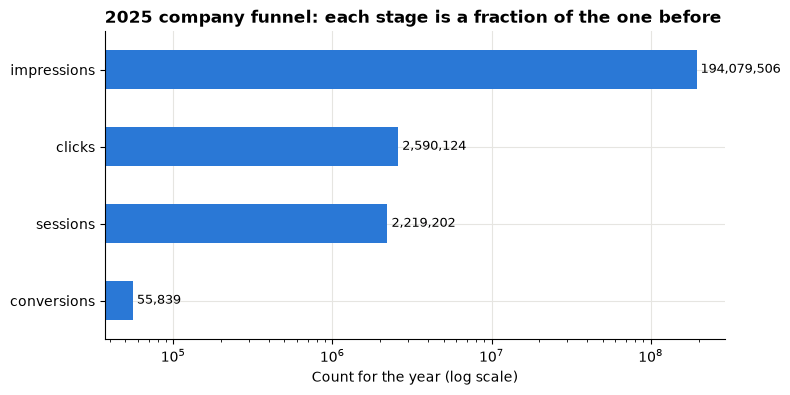

In [7]:
stages = ["impressions", "clicks", "sessions", "conversions"]
company = daily[stages].sum()

ax = company.plot.barh(logx=True, color="#2a78d6")
ax.invert_yaxis()
ax.set_title("2025 company funnel: each stage is a fraction of the one before")
ax.set_xlabel("Count for the year (log scale)")
for i, value in enumerate(company):
    ax.text(value, i, f" {value:,.0f}", va="center", fontsize=9)
plt.show()

---

## Part 3: Funnel rates are ratios of sums

Each rate divides one funnel count by another. The rule from Session 5 applies everywhere: **add up the numerator, add up the denominator, then divide**. Never add up or average rates.

| Rate | Formula | Read it as | Better when |
|---|---|---|---|
| **CTR** (click-through rate) | clicks ÷ impressions | share of showings that got a click | higher |
| **Conversion rate** | conversions ÷ sessions | share of visits that bought | higher |
| **CPC** (cost per click) | spend ÷ clicks | currency units paid per click | lower |
| **CPA** (cost per acquisition) | spend ÷ conversions | currency units paid per purchase | lower |
| **ROAS** (return on ad spend) | attributed revenue ÷ spend | revenue credited per unit of spend | higher |

The helper `add_rates()` from the setup cell does exactly this to any table of **summed** counts. Here it is on the company total for the year:

In [8]:
company_total = add_rates(daily[COUNTS].sum().to_frame("All campaigns").T)
show(company_total)

,spend,impressions,clicks,sessions,conversions,attributed_revenue,CTR,conv_rate,CPC,CPA,ROAS
All campaigns,"1,469,925.58","194,079,506","2,590,124","2,219,202","55,839","6,049,101.43",1.33%,2.52%,0.57,26.32,4.12


Read the table above as sentences: "of every 100 times an ad was shown, about this many got a click"; "each purchase cost this many currency units of media". Two rates combine counts the other rates do not: CPA and ROAS both depend on **spend**, so a campaign that costs almost nothing can look spectacular on them.

> **Check your understanding 1**
>
> A campaign had 200,000 impressions, 2,000 clicks, 1,600 sessions, 40 conversions, spend of 1,000 and attributed revenue of 3,200. Work out its CTR, conversion rate, CPC, CPA and ROAS by hand.

---

## Part 4: Zero denominators and review cases

Some days a campaign was paused: nothing was shown and nothing was spent. On those days CPC, CPA and ROAS have a **zero denominator**.

> **Predict, then reveal**
>
> What does pandas give for 500 ÷ 0? And for 0 ÷ 0? Will it raise an error?

In [9]:
demo = pd.DataFrame({"revenue": [500.0, 0.0, 500.0], "spend": [0.0, 0.0, 100.0]})
demo["plain division"] = demo["revenue"] / demo["spend"]
demo["safe_div"] = safe_div(demo["revenue"], demo["spend"])
demo

,revenue,spend,plain division,safe_div
0,500.00,0.00,inf,NaN
1,0.00,0.00,NaN,NaN
2,500.00,100.00,5.00,5.00


Plain division gives `inf` (infinity) or `NaN` **without any error**. An `inf` that slips into an average or a chart wrecks it silently, and a zero typed in instead of a blank would rank a paused campaign as "free". The course rule:

> **A zero denominator gives "not available" (a blank), never 0 and never infinity.** `safe_div()` does this.

Now count the rows where each denominator is zero:

In [10]:
zero_cases = pd.Series({
    "spend = 0 (ROAS, CPC, CPA not available)": (daily["spend"] == 0).sum(),
    "clicks = 0 (CPC not available)": (daily["clicks"] == 0).sum(),
    "conversions = 0 (CPA not available)": (daily["conversions"] == 0).sum(),
    "spend = 0 but conversions > 0 (review cases)": ((daily["spend"] == 0) & (daily["conversions"] > 0)).sum(),
}, name="rows")
zero_cases.to_frame()

,rows
"spend = 0 (ROAS, CPC, CPA not available)",39
clicks = 0 (CPC not available),27
conversions = 0 (CPA not available),112
spend = 0 but conversions > 0 (review cases),12


In [11]:
review = daily[(daily["spend"] == 0) & (daily["conversions"] > 0)]
print("Campaigns with review cases:", review["campaign_id"].unique())
review[["date", "campaign_id", "spend", "impressions", "sessions", "conversions", "attributed_revenue"]].head()

Campaigns with review cases: ['EML-01']


,date,campaign_id,spend,impressions,sessions,conversions,attributed_revenue
666,2025-04-06,EML-01,0.00,66810,452,6,466.08
883,2025-05-07,EML-01,0.00,66658,477,7,601.93
932,2025-05-14,EML-01,0.00,66808,538,10,920.63
1023,2025-05-27,EML-01,0.00,66610,524,8,767.31
1128,2025-06-11,EML-01,0.00,66789,526,15,"1,355.61"


The **review cases** above are days with sales but no media cost. They all belong to the Email campaign: free-send days, when a newsletter went out without any paid cost. They are real activity, so they stay in the campaign totals, but no daily ROAS exists for them. **Report them; do not compute ROAS for them; do not delete them.**

Most `conversions = 0` days come from small or weak campaigns. Their CPA is not available for that day; over a whole month or year the campaign usually has some conversions, so its total CPA exists.

> **Check your understanding 2**
>
> A dashboard shows CPA = 0 for a campaign that had spend but no conversions last week, and ranks it "most efficient". What went wrong, and what should the cell show?

---

## Part 5: The campaign scorecard

Now the totals for each campaign. `groupby` adds up the counts first; `add_rates` divides the sums.

In [12]:
by_campaign = add_rates(daily.groupby(["channel", "campaign_id"])[COUNTS].sum())
show(by_campaign[["spend", "sessions", "conversions", "attributed_revenue", "conv_rate", "CPA", "ROAS"]])

spend sessions conversions attributed_revenue  \
channel campaign_id                                                       
Display DISP-01      207,555.98  179,711       1,518         132,218.98   
Email   EML-01        15,426.37  201,704       4,378         451,164.11   
Search  SRCH-01      362,654.08  679,463      24,629       2,897,731.90   
        SRCH-02      256,844.20  487,457      15,308       1,589,252.73   
Social  SOC-01       433,453.56  556,007       6,408         595,049.96   
        SOC-02        24,001.47   45,313       2,850         315,601.00   
Video   VID-01       169,989.92   69,547         748          68,082.75   

                    conv_rate     CPA   ROAS  
channel campaign_id                           
Display DISP-01         0.84%  136.73   0.64  
Email   EML-01          2.17%    3.52  29.25  
Search  SRCH-01         3.62%   14.72   7.99  
        SRCH-02         3.14%   16.78   6.19  
Social  SOC-01          1.15%   67.64   1.37  
        SOC-02          6.29%    8.42  13.15  
Video   VID-01          1.08%  227.26   0.40

Before reading the scorecard, check that it **reconciles**: the campaign totals must add up to the company total from Part 3.

In [13]:
for col in ["spend", "conversions", "attributed_revenue"]:
    print(f"{col:20s} campaigns add up to company total: {np.isclose(by_campaign[col].sum(), company_total[col].iloc[0])}")

spend                campaigns add up to company total: True
conversions          campaigns add up to company total: True
attributed_revenue   campaigns add up to company total: True


Now look at the Email row in the scorecard. Its ROAS is far above every other campaign's.

> **Predict, then reveal**
>
> Is Email really many times better at turning money into revenue? Look at its **spend** column compared with the others before you answer.

In [14]:
share = by_campaign[["spend", "conversions"]] / by_campaign[["spend", "conversions"]].sum()
share.columns = ["share of spend", "share of conversions"]
show(share.join(by_campaign[["ROAS"]]))

share of spend share of conversions   ROAS
channel campaign_id                                           
Display DISP-01             14.12%                2.72%   0.64
Email   EML-01               1.05%                7.84%  29.25
Search  SRCH-01             24.67%               44.11%   7.99
        SRCH-02             17.47%               27.41%   6.19
Social  SOC-01              29.49%               11.48%   1.37
        SOC-02               1.63%                5.10%  13.15
Video   VID-01              11.56%                1.34%   0.40

Email takes a tiny share of the spend but a sizeable share of the conversions. Its "spend" covers only a small sending cost; it does not include the cost of building the mailing list, writing the emails or the discounts they offer, and its free-send days add revenue with no spend at all. A ratio with a **tiny denominator** looks extreme. ROAS for Email is not comparable with ROAS for paid media; say so instead of ranking it first.

> **Check your understanding 3**
>
> Email's ROAS is the highest by far. Give two reasons why "move the Search budget into Email" would not work.

---

## Part 6: Weighted rate versus the mean of campaign rates

The marketing lead asks for conversion rate **by channel**. Two channels, Search and Social, have two campaigns each. There are two ways to get a channel's rate:

| Method | How | Problem |
|---|---|---|
| **Mean of campaign rates** | compute each campaign's rate, then average them | gives a tiny campaign the same vote as a huge one |
| **Weighted rate (ratio of sums)** | add the channel's conversions and sessions, then divide | none: it is the channel's actual rate |

> **Predict, then reveal**
>
> Look back at the scorecard in Part 5. Social has one big campaign with a low conversion rate (SOC-01, a broad audience) and one small campaign with a very high rate (SOC-02, past visitors). On the **mean of campaign rates**, will Social beat Search? On the **weighted rate**?

In [15]:
campaign_rate = by_campaign["conv_rate"].groupby("channel").mean()
channel = add_rates(daily.groupby("channel")[COUNTS].sum())

compare = pd.DataFrame({
    "campaigns": by_campaign.groupby("channel").size(),
    "sessions": channel["sessions"],
    "mean of campaign rates": campaign_rate,
    "weighted rate (sum ÷ sum)": channel["conv_rate"],
}).sort_values("weighted rate (sum ÷ sum)", ascending=False)
compare.assign(sessions=compare["sessions"].map("{:,.0f}".format),
               **{c: compare[c].map("{:.2%}".format) for c in ["mean of campaign rates", "weighted rate (sum ÷ sum)"]})

,campaigns,sessions,mean of campaign rates,weighted rate (sum ÷ sum)
channel,,,,
Search,2,"1,166,920",3.38%,3.42%
Email,1,"201,704",2.17%,2.17%
Social,2,"601,320",3.72%,1.54%
Video,1,"69,547",1.08%,1.08%
Display,1,"179,711",0.84%,0.84%


Read the table above. For channels with a single campaign, the two methods agree. For **Social** they do not: the mean of campaign rates lifts Social above Search, while the weighted rate puts it well below. The chart shows why.

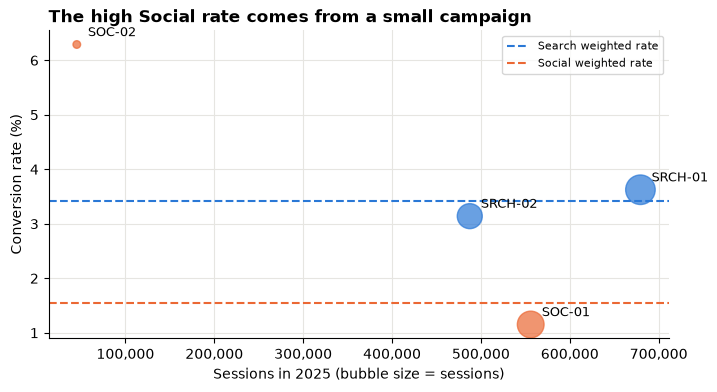

In [16]:
social_search = by_campaign.loc[["Search", "Social"]].reset_index()

fig, ax = plt.subplots(figsize=(8, 4))
colors = social_search["channel"].map({"Search": "#2a78d6", "Social": "#eb6834"})
ax.scatter(social_search["sessions"], social_search["conv_rate"] * 100,
           s=social_search["sessions"] / 1500, c=colors, alpha=0.7)
for _, row in social_search.iterrows():
    ax.annotate(row["campaign_id"], (row["sessions"], row["conv_rate"] * 100),
                textcoords="offset points", xytext=(8, 6), fontsize=9)
for name, color in [("Search", "#2a78d6"), ("Social", "#eb6834")]:
    ax.axhline(channel.loc[name, "conv_rate"] * 100, color=color, linestyle="--",
               label=f"{name} weighted rate")
ax.set_title("The high Social rate comes from a small campaign")
ax.set_xlabel("Sessions in 2025 (bubble size = sessions)")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_ylabel("Conversion rate (%)")
ax.legend(fontsize=8)
plt.show()

SOC-02 sits high on the chart but far to the left: it has very few sessions. The mean of rates treats SOC-02 and SOC-01 as equals, so the small campaign's high rate drags the "Social" figure up. The weighted rate gives each **session** one vote, so SOC-01's large volume dominates, as it does in the real business.

> **The rule**
>
> To combine rates across campaigns, days, regions or anything else, **add the numerators and the denominators, then divide**. A mean of rates answers a different question ("what does a typical campaign look like?"), which is rarely what a manager means by "the channel's rate".

There is a second lesson in SOC-02's name: it targets **past visitors**, people who already know the shop. Such campaigns usually convert well because their audience was already likely to buy. That leads to the next part.

> **Check your understanding 4**
>
> A regional manager averages the conversion rates of her ten stores' websites and reports it as "the region's conversion rate". When would that number be close to the true regional rate, and when would it be far off?

---

## Part 7: Attribution, and what ROAS does not tell you

`attributed_revenue` is revenue **credited** to a campaign. In this data the rule is simple: each purchase belongs to exactly **one** campaign, on the same day. Real attribution is messier, and the simple rule hides questions the table cannot answer.

| The table **can** tell you | The table **cannot** tell you |
|---|---|
| How much revenue was credited to each campaign | Whether the buyer saw other campaigns first (there is no touchpoint history) |
| Cost per credited purchase (CPA) | Whether the buyer would have bought anyway, without the ad |
| Revenue credited per unit of spend (ROAS) | Sales from people who came on their own (there is no organic traffic) |
| Trends in these numbers over time | Whether last-click or any multi-touch rule would credit the same campaign |

So this table **cannot prove** a last-click or multi-touch claim, and it cannot measure **incrementality**: the sales that happened **because of** the campaign and would not have happened without it.

### ROAS is not profit

ROAS divides revenue by **media** spend only. It ignores:

1. **Product cost**: a ROAS of 3 means little if the products cost 80% of their price to make or buy.
2. **Returns**: attributed revenue is counted **before** returns.
3. **Other costs**: agency fees, creative production, discounts and staff time.

### ROAS is not causal lift

A high ROAS says "a lot of revenue was **credited** here", not "the spend **caused** this revenue". A campaign aimed at past visitors can show a high ROAS while adding few extra sales, because many of those people were going to buy anyway.

> **Predict, then reveal**
>
> In a previous session we saw that spend and revenue both rise late in the year. If you compared ROAS in the busiest months with ROAS earlier in the year, could you tell how much of the change came from the budget and how much from the season?

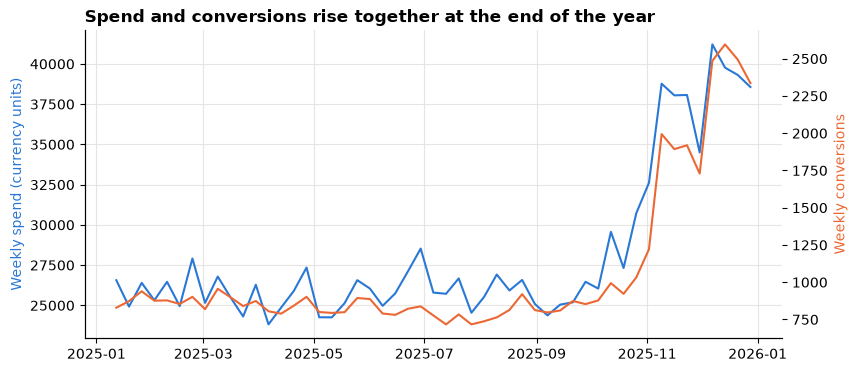

In [17]:
weekly = daily.set_index("date").resample("W-SUN")[["spend", "conversions"]].sum()   # weeks ending on Sunday
weekly = weekly.loc["2025-01-12":"2025-12-28"]          # complete Monday-to-Sunday weeks only

fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(weekly.index, weekly["spend"], color="#2a78d6", label="Spend")
ax1.set_ylabel("Weekly spend (currency units)", color="#2a78d6")
ax2 = ax1.twinx()
ax2.plot(weekly.index, weekly["conversions"], color="#eb6834", label="Conversions")
ax2.set_ylabel("Weekly conversions", color="#eb6834")
ax2.grid(False)
ax1.set_title("Spend and conversions rise together at the end of the year")
plt.show()

Both lines climb in the last months of the year. Budgets went up **and** shoppers were in a buying mood at the same time, so a before/after comparison would give the budget credit for the season. This is the **confounding** you met in Session 8: season drives both spend and sales.

> **Check your understanding 5**
>
> A colleague says: "SOC-02's ROAS is many times SOC-01's, so every unit we move from SOC-01 to SOC-02 earns that many times more." Name two separate reasons this may be false.

---

## Part 8: From comparison to experiment

Everything so far is an **observational comparison**: we looked at what happened. It can point to candidates, but it cannot say what **more** (or less) money would do. For that, Session 9's tool is the right one: a **controlled test**.

| Design | How it works for a budget change | Watch out for |
|---|---|---|
| **Holdout** | Randomly keep a share of the target audience from seeing the campaign; compare their purchases with those who see it | Needs a platform that can hold people out; small effects need big groups |
| **Geo split** | Randomly pick some regions to get the extra budget and some to stay as they are; compare sales, not attributed revenue | Regions differ; pick matched pairs and compare **change** from before |
| **Time switching** | Alternate the budget on and off week by week | Seasons and holidays; carry-over from earlier weeks |

A test proposal answers six questions **before** it starts:

1. **Change:** what exactly changes (for example "raise campaign X's daily budget by a fifth")?
2. **Design:** who or which regions get the change, chosen at random?
3. **Primary metric:** one number decided in advance, ideally **total** conversions or revenue in the test group, not attributed revenue.
4. **Guardrails:** numbers that must not get worse (CPA, return rate, unsubscribes, complaints).
5. **Duration:** long enough for enough conversions and at least whole weeks; avoid big holidays unless they are the point.
6. **Decision rule:** what result leads to "scale up", "keep as is" or "stop", including the uncertainty interval from Session 9.

> **Check your understanding 6**
>
> Why should the primary metric be **total** conversions in the test regions rather than revenue **attributed** to the campaign?

---

## Part 9: Worked case — a scorecard the lead can use

We combine everything into one scorecard. It keeps **volumes next to rates**, keeps blanks as "n/a", flags Email as not comparable, and sorts by conversions so the campaigns that move the business are at the top.

In [18]:
scorecard = by_campaign[["spend", "conversions", "attributed_revenue", "conv_rate", "CPA", "ROAS"]].copy()
scorecard["share of conversions"] = scorecard["conversions"] / scorecard["conversions"].sum()
scorecard["note"] = ""
scorecard.loc[scorecard.index.get_level_values("channel") == "Email", "note"] = "near-zero media cost: ROAS not comparable"
scorecard = scorecard.sort_values("conversions", ascending=False)
show(scorecard)

spend conversions attributed_revenue conv_rate  \
channel campaign_id                                                        
Search  SRCH-01      362,654.08      24,629       2,897,731.90     3.62%   
        SRCH-02      256,844.20      15,308       1,589,252.73     3.14%   
Social  SOC-01       433,453.56       6,408         595,049.96     1.15%   
Email   EML-01        15,426.37       4,378         451,164.11     2.17%   
Social  SOC-02        24,001.47       2,850         315,601.00     6.29%   
Display DISP-01      207,555.98       1,518         132,218.98     0.84%   
Video   VID-01       169,989.92         748          68,082.75     1.08%   

                        CPA   ROAS share of conversions  \
channel campaign_id                                       
Search  SRCH-01       14.72   7.99               44.11%   
        SRCH-02       16.78   6.19               27.41%   
Social  SOC-01        67.64   1.37               11.48%   
Email   EML-01         3.52  29.25                7.84%   
Social  SOC-02         8.42  13.15                5.10%   
Display DISP-01      136.73   0.64                2.72%   
Video   VID-01       227.26   0.40                1.34%   

                                                          note  
channel campaign_id                                             
Search  SRCH-01                                                 
        SRCH-02                                                 
Social  SOC-01                                                  
Email   EML-01       near-zero media cost: ROAS not comparable  
Social  SOC-02                                                  
Display DISP-01                                                 
Video   VID-01

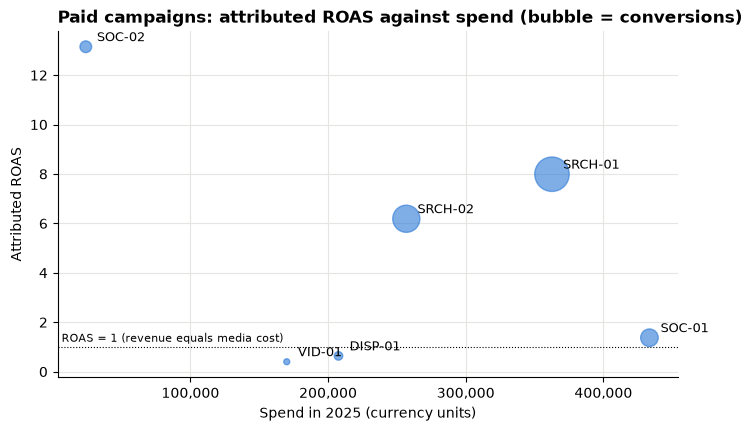

In [19]:
paid = scorecard.drop("Email", level="channel").reset_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(paid["spend"], paid["ROAS"], s=paid["conversions"] / 40, alpha=0.6, color="#2a78d6")
for _, row in paid.iterrows():
    ax.annotate(row["campaign_id"], (row["spend"], row["ROAS"]),
                textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.axhline(1, color="black", linewidth=0.8, linestyle=":")
ax.text(ax.get_xlim()[0], 1.1, " ROAS = 1 (revenue equals media cost)", ha="left", va="bottom", fontsize=8)
ax.set_title("Paid campaigns: attributed ROAS against spend (bubble = conversions)")
ax.set_xlabel("Spend in 2025 (currency units)")
ax.xaxis.set_major_formatter("{x:,.0f}")
ax.set_ylabel("Attributed ROAS")
plt.show()

How to read the chart: campaigns at the top right are **efficient and large**; at the top left, **efficient but small**; at the bottom right, **large but expensive**. The dotted line marks where credited revenue only just equals media cost. Remember it is **not** a profit line: product cost and returns are missing.

A recommendation built from this scorecard, in the form the lead asked for:

> 1. **What the data show:** name the campaigns that combine high volume with a low CPA, and the large campaigns whose ROAS is close to or below 1, using the numbers in the scorecard.
> 2. **What they do not show:** attributed revenue is not incremental; Email and past-visitor campaigns may get credit for buyers who would have bought anyway; ROAS is before product cost and returns.
> 3. **What to do:** test one bounded budget change on one candidate (design, primary metric, guardrails, duration and decision rule), rather than reallocating the whole budget.

---

## Summary

| Question | Tool | Trap to avoid |
|---|---|---|
| Can I trust the table? | Key, completeness and funnel-order checks | Computing rates before checking the grain |
| What is the rate for a campaign, channel or year? | Ratio of sums (`add_rates`) | Averaging or adding rates |
| What if the denominator is zero? | `safe_div`: blank, "not available" | Showing 0 or infinity; deleting review cases |
| Which channel converts best? | Weighted rate with volumes shown | Mean of campaign rates (the SOC-02 effect) |
| Which campaign is most efficient? | CPA and ROAS **with** spend and conversions | Ranking a tiny-cost campaign (Email) first |
| Did the spend cause the sales? | A controlled test (holdout, geo split) | Treating attributed revenue or ROAS as incremental |
| Is it profitable? | Needs product cost, returns, other costs | Reading ROAS as profit |

---

## Quiz

Answer these at the start of the next lecture, which opens the **HR case**: headcount and staff turnover. You do not need any HR knowledge; use common sense. Write short answers.

1. A team had 40 people on 1 January and 44 on 31 December. Does that mean only 4 people joined during the year? Explain.
2. **Headcount** can be counted on one day, or averaged over a period. Why might the two differ for a shop that hires many seasonal staff?
3. 6 people left a team during the year. Is the turnover rate 6 ÷ (headcount today)? What would be a fairer denominator, and why?
4. A department of 5 people lost 2 people; a department of 200 lost 30. Which has the higher turnover rate, and which number would you trust more?
5. Why might an HR report hide numbers for groups with only two or three people?

---

## Lab briefing

In the **Lab** you:

1. Load the campaign table and check its key, completeness and funnel order.
2. Build campaign and channel totals with ratios of sums, and reconcile them to the company total.
3. Find the zero-denominator rows and the Email review cases.
4. Compare the mean of campaign rates with the weighted rate by channel and explain the difference.
5. Build a CPA and ROAS scorecard with volumes; Stretch: a monthly trend and a spend-band view.
6. Challenge: debug three broken ROAS analyses, then write a controlled test proposal.

Open the [Session 12 lab](12_marketing_campaigns_lab.md).